In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/Tweets.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [3]:


print("Dataset shape:", df.shape)


print("\nColumn names:")
print(df.columns.tolist())


df.head()

Dataset shape: (14640, 15)

Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [4]:

print("Missing values in each column:")
print(df.isnull().sum())


print("\nDuplicate rows:", df.duplicated().sum())


print("\nDataset information:")
df.info()

Missing values in each column:
tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
negativereason                   5462
negativereason_confidence        4118
airline                             0
airline_sentiment_gold          14600
name                                0
negativereason_gold             14608
retweet_count                       0
text                                0
tweet_coord                     13621
tweet_created                       0
tweet_location                   4733
user_timezone                    4820
dtype: int64

Duplicate rows: 36

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  str    
 2   airli

In [5]:
#count tweet in each sentiment
print(df["airline_sentiment"].value_counts())

# % show krega har sentiment ki
print("\nSentiment percentages:")
print(
    (df["airline_sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)

#kuch tweet ko check krne k lie
df[["text", "airline_sentiment"]].head(10)

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Sentiment percentages:
airline_sentiment
negative    62.69
neutral     21.17
positive    16.14
Name: proportion, dtype: float64


,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative
5,@VirginAmerica seriously would pay $30 a fligh...,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",positive
7,@VirginAmerica Really missed a prime opportuni...,neutral
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive
9,"@VirginAmerica it was amazing, and arrived an ...",positive


airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


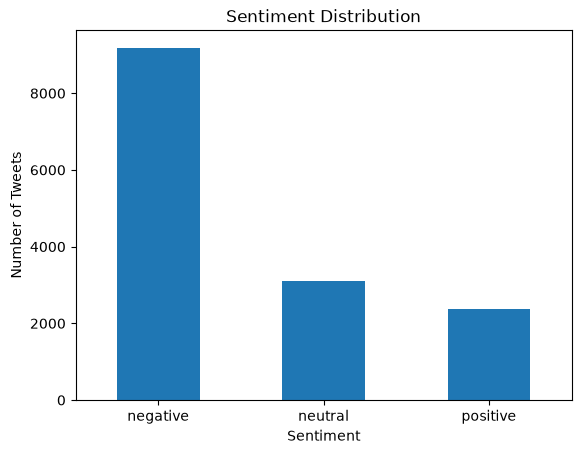

In [6]:
import matplotlib.pyplot as plt

sentiment_counts = df["airline_sentiment"].value_counts()

print(sentiment_counts)

sentiment_counts.plot(kind="bar")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.show()

In [7]:

for tweet in df["text"].head(5):
    print(tweet)
    print("-" * 80)

@VirginAmerica What @dhepburn said.
--------------------------------------------------------------------------------
@VirginAmerica plus you've added commercials to the experience... tacky.
--------------------------------------------------------------------------------
@VirginAmerica I didn't today... Must mean I need to take another trip!
--------------------------------------------------------------------------------
@VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
--------------------------------------------------------------------------------
@VirginAmerica and it's a really big bad thing about it
--------------------------------------------------------------------------------


In [8]:
df[["text", "airline_sentiment"]].head(5)

,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


In [9]:
import html
import re

def clean_tweet(text):
    text = html.unescape(text)
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["text"].apply(clean_tweet)

In [10]:
#verifying 
df[["text", "clean_text", "airline_sentiment"]].head(10)

,text,clean_text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,What said.,neutral
1,@VirginAmerica plus you've added commercials t...,plus you've added commercials to the experienc...,positive
2,@VirginAmerica I didn't today... Must mean I n...,I didn't today... Must mean I need to take ano...,neutral
3,@VirginAmerica it's really aggressive to blast...,"it's really aggressive to blast obnoxious ""ent...",negative
4,@VirginAmerica and it's a really big bad thing...,and it's a really big bad thing about it,negative
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay $30 a flight for seats tha...,negative
6,"@VirginAmerica yes, nearly every time I fly VX...","yes, nearly every time I fly VX this “ear worm...",positive
7,@VirginAmerica Really missed a prime opportuni...,Really missed a prime opportunity for Men With...,neutral
8,"@virginamerica Well, I didn't…but NOW I DO! :-D","Well, I didn't…but NOW I DO! :-D",positive
9,"@VirginAmerica it was amazing, and arrived an ...","it was amazing, and arrived an hour early. You...",positive


In [11]:

print("Missing cleaned tweets:", df["clean_text"].isnull().sum())


print(
    "Blank cleaned tweets:",
    df["clean_text"].str.strip().eq("").sum()
)

print(
    "Missing sentiment labels:",
    df["airline_sentiment"].isnull().sum()
)

Missing cleaned tweets: 0
Blank cleaned tweets: 0
Missing sentiment labels: 0


In [12]:

print(
    "Duplicate cleaned tweets:",
    df["clean_text"].duplicated().sum()
)

Duplicate cleaned tweets: 345


In [13]:
dup_mask = df["clean_text"].duplicated(keep=False)

dup_df = df.loc[
    dup_mask,
    ["clean_text", "airline_sentiment"]
].sort_values("clean_text")

dup_df.head(20)

,clean_text,airline_sentiment
12134,"""Airport snow removal method #22..."" Keep up t...",positive
9025,"""Airport snow removal method #22..."" Keep up t...",neutral
558,"""Airport snow removal method #22..."" Keep up t...",positive
11973,"""Airport snow removal method #22..."" Keep up t...",positive
8615,"'s CEO #pilots among ardent fans, Wall Street ...",neutral
8143,"'s CEO #pilots among ardent fans, Wall Street ...",neutral
8700,'s CEO Battles to Appease Passengers and Wall ...,neutral
8931,'s CEO Battles to Appease Passengers and Wall ...,neutral
5642,'s CEO Kelly draws record crowd to Business Pa...,neutral
5643,'s CEO Kelly draws record crowd to Business Pa...,neutral


In [14]:
label_counts = df.groupby("clean_text")["airline_sentiment"].nunique()

conflicting_tweets = label_counts[label_counts > 1]

print("Unique cleaned tweets with conflicting labels:", len(conflicting_tweets))

Unique cleaned tweets with conflicting labels: 37


In [15]:
conflict_texts = conflicting_tweets.index

conflict_df = df[
    df["clean_text"].isin(conflict_texts)
][["clean_text", "airline_sentiment"]]

conflict_df.sort_values("clean_text").head(20)

,clean_text,airline_sentiment
11973,"""Airport snow removal method #22..."" Keep up t...",positive
9025,"""Airport snow removal method #22..."" Keep up t...",neutral
12134,"""Airport snow removal method #22..."" Keep up t...",positive
558,"""Airport snow removal method #22..."" Keep up t...",positive
8431,'s CEO battles to appease passengers and Wall ...,negative
8824,'s CEO battles to appease passengers and Wall ...,positive
8123,'s CEO battles to appease passengers and Wall ...,neutral
8596,'s CEO battles to appease passengers and Wall ...,neutral
8307,'s CEO battles to appease passengers and Wall ...,neutral
8109,'s CEO battles to appease passengers and Wall ...,neutral


In [16]:
conflict_sample = df[
    df["clean_text"].isin(conflicting_tweets.index)
][["text", "clean_text", "airline_sentiment"]]

conflict_sample.sort_values("clean_text").head(10)

,text,clean_text,airline_sentiment
11973,"@AmericanAir ""Airport snow removal method #22....","""Airport snow removal method #22..."" Keep up t...",positive
9025,"@USAirways ""Airport snow removal method #22......","""Airport snow removal method #22..."" Keep up t...",neutral
12134,"@AmericanAir ""Airport snow removal method #22....","""Airport snow removal method #22..."" Keep up t...",positive
558,"@united ""Airport snow removal method #22...""\n...","""Airport snow removal method #22..."" Keep up t...",positive
8431,@JetBlue's CEO battles to appease passengers a...,'s CEO battles to appease passengers and Wall ...,negative
8824,@JetBlue's CEO battles to appease passengers a...,'s CEO battles to appease passengers and Wall ...,positive
8123,@JetBlue's CEO battles to appease passengers a...,'s CEO battles to appease passengers and Wall ...,neutral
8596,@JetBlue's CEO battles to appease passengers a...,'s CEO battles to appease passengers and Wall ...,neutral
8307,@JetBlue's CEO battles to appease passengers a...,'s CEO battles to appease passengers and Wall ...,neutral
8109,@JetBlue's CEO battles to appease passengers a...,'s CEO battles to appease passengers and Wall ...,neutral


In [17]:
tweet_summary = df.groupby("clean_text").agg(
    total_occurrences=("airline_sentiment", "size"),
    unique_labels=("airline_sentiment", "nunique")
)

print("Total unique cleaned tweets:", len(tweet_summary))

print(
    "Repeated cleaned tweets:",
    (tweet_summary["total_occurrences"] > 1).sum()
)

print(
    "Repeated tweets with conflicting labels:",
    (
        (tweet_summary["total_occurrences"] > 1)
        & (tweet_summary["unique_labels"] > 1)
    ).sum()
)

Total unique cleaned tweets: 14295
Repeated cleaned tweets: 221
Repeated tweets with conflicting labels: 37


In [18]:
conflict_details = (
    df[df["clean_text"].isin(conflicting_tweets.index)]
    .groupby(["clean_text", "airline_sentiment"])
    .size()
    .unstack(fill_value=0)
)

conflict_details.head(10)

airline_sentiment,negative,neutral,positive
clean_text,,,
"""Airport snow removal method #22..."" Keep up the good work folks, this is where Cessna's become 747's!",0,1,3
's CEO battles to appease passengers and Wall Street -,1,1,1
's CEO battles to appease passengers and Wall Street - Waterbury Republican American,1,8,0
- keeping AA up in the Air! My crew chief cousin Alex Espinosa in DFW!,0,1,1
"AA doesnt charge any fees to change award tickets as long as the origin, destination & award type remains the same",0,1,1
"Believe me, I understand. Flight #2955. Was originally booked for Sunday. Flight was Cancelled Flighted and rescheduled for today.",1,0,1
Congratulations!,0,1,1
I DM'd you,1,1,0
I don't think you should help him at all based on his behavior. The voucher and cot seem like enough lol 😃,0,1,1


In [19]:
print("Total conflicting cleaned texts:", len(conflict_details))

print(
    "Total rows in conflicting groups:",
    conflict_details.sum().sum()
)

print(
    "Rows belonging to conflicting groups:",
    df["clean_text"].isin(conflicting_tweets.index).sum()
)

Total conflicting cleaned texts: 37
Total rows in conflicting groups: 142
Rows belonging to conflicting groups: 142


In [20]:
conflict_originals = df[
    df["clean_text"].isin(conflicting_tweets.index)
]

conflict_originals[
    ["text", "clean_text", "airline_sentiment"]
].head(15)

,text,clean_text,airline_sentiment
109,"@VirginAmerica has getaway deals through May, ...","has getaway deals through May, from $59 one-wa...",positive
110,"@VirginAmerica has getaway deals through May, ...","has getaway deals through May, from $59 one-wa...",neutral
111,"@VirginAmerica has getaway deals through May, ...","has getaway deals through May, from $59 one-wa...",positive
112,"@VirginAmerica has getaway deals through May, ...","has getaway deals through May, from $59 one-wa...",neutral
193,@VirginAmerica thanks!,thanks!,positive
324,@VirginAmerica @SSal thanks!,thanks!,positive
366,@VirginAmerica I have 2d and 3d embossed badge...,I have 2d and 3d embossed badges and patches s...,negative
395,@VirginAmerica thank you,thank you,positive
504,@united thanks,thanks,positive
515,@united thanks,thanks,positive


In [21]:
original_label_counts = (
    df.groupby("text")["airline_sentiment"].nunique()
)

print(
    "Original identical tweets with conflicting labels:",
    (original_label_counts > 1).sum()
)

Original identical tweets with conflicting labels: 25


In [22]:
original_conflicts = df[
    df["text"].isin(
        original_label_counts[original_label_counts > 1].index
    )
][["text", "airline_sentiment"]]

original_conflicts.sort_values("text").head(20)

,text,airline_sentiment
11962,@AmericanAir - keeping AA up in the Air! My cr...,neutral
12123,@AmericanAir - keeping AA up in the Air! My cr...,positive
12130,@AmericanAir @Clarkey_19 we done it with 1 tru...,positive
11969,@AmericanAir @Clarkey_19 we done it with 1 tru...,neutral
11939,@AmericanAir @RobertDwyer AA doesnt charge any...,positive
12100,@AmericanAir @RobertDwyer AA doesnt charge any...,neutral
12047,"@AmericanAir Believe me, I understand. Flight ...",negative
11886,"@AmericanAir Believe me, I understand. Flight ...",positive
12080,@AmericanAir I don't think you should help him...,neutral
11919,@AmericanAir I don't think you should help him...,positive


In [23]:

print("Exact duplicate original tweets:", df["text"].duplicated().sum())


print("Exact duplicate full rows:", df.duplicated().sum())

Exact duplicate original tweets: 213
Exact duplicate full rows: 36


In [24]:
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("After removing exact duplicate rows:", df_clean.shape)
print("Exact duplicate full rows remaining:", df_clean.duplicated().sum())

Original dataset shape: (14640, 16)
After removing exact duplicate rows: (14604, 16)
Exact duplicate full rows remaining: 0


In [25]:
print("Missing text:", df_clean["text"].isna().sum())
print("Missing cleaned text:", df_clean["clean_text"].isna().sum())
print("Missing sentiment labels:", df_clean["airline_sentiment"].isna().sum())

print("\nSentiment distribution:")
print(df_clean["airline_sentiment"].value_counts())

Missing text: 0
Missing cleaned text: 0
Missing sentiment labels: 0

Sentiment distribution:
airline_sentiment
negative    9159
neutral     3091
positive    2354
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

X = df_clean["clean_text"]
y = df_clean["airline_sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 11683
Testing samples: 2921


In [27]:

overlap = set(X_train).intersection(set(X_test))

print("Tweets appearing in both sets:", len(overlap))


Tweets appearing in both sets: 73


In [28]:

from sklearn.model_selection import GroupShuffleSplit

X = df_clean["clean_text"]
y = df_clean["airline_sentiment"]
groups = df_clean["clean_text"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

overlap = set(X_train).intersection(set(X_test))

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Tweets appearing in both sets:", len(overlap))


Training samples: 11688
Testing samples: 2916
Tweets appearing in both sets: 0


In [29]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)


Training data shape: (11688, 5000)
Testing data shape: (2916, 5000)


In [30]:

print("Vocabulary size:", len(tfidf.vocabulary_))
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Vocabulary size: 5000
Training matrix: (11688, 5000)
Testing matrix: (2916, 5000)
Training labels: (11688,)
Testing labels: (2916,)


In [31]:

assert X_train_tfidf.shape[0] == len(y_train)
assert X_test_tfidf.shape[0] == len(y_test)
assert X_train_tfidf.shape[1] == X_test_tfidf.shape[1]
assert len(set(X_train).intersection(set(X_test))) == 0

print("All preprocessing checks passed!")


All preprocessing checks passed!


In [32]:
print(X_train.shape)
print(y_train.shape)

(11688,)
(11688,)


In [33]:
print(type(X_train))
print(X_train.shape)
print(X_train[:2])

<class 'pandas.Series'>
(11688,)
0                                           What said.
1    plus you've added commercials to the experienc...
Name: clean_text, dtype: str


In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["clean_text"].fillna(""))

print("TF-IDF shape:", X.shape)

TF-IDF shape: (14640, 5000)


In [35]:
print(df.columns.tolist())

['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone', 'clean_text']


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    df["airline_sentiment"],
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (11712, 5000)
Testing features: (2928, 5000)
Training labels: (11712,)
Testing labels: (2928,)


In [37]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [38]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
['positive' 'negative' 'negative' 'neutral' 'neutral' 'negative'
 'negative' 'neutral' 'negative' 'positive']


In [39]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy of model is:", round(accuracy * 100, 2), "%")

Accuracy of model is: 80.02 %


In [40]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.83      0.93      0.88      1889
     neutral       0.66      0.52      0.58       580
    positive       0.81      0.61      0.70       459

    accuracy                           0.80      2928
   macro avg       0.77      0.69      0.72      2928
weighted avg       0.79      0.80      0.79      2928



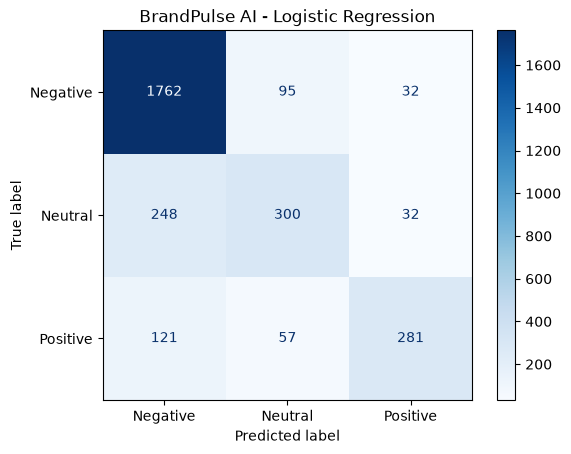

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues")
plt.title("BrandPulse AI - Logistic Regression")
plt.show()

In [42]:
new_tweet = ["I  love this airline, the service was  amazing!"]

new_tweet_tfidf = tfidf.transform(new_tweet)

prediction = model.predict(new_tweet_tfidf)

print("Tweet:", new_tweet[0])
print("Predicted Sentiment:", prediction[0])

Tweet: I  love this airline, the service was  amazing!
Predicted Sentiment: positive


In [43]:
test_tweets = [
    "I love this airline, amazing service!",
    "The flight was delayed and the staff was rude.",
    "The flight was okay, nothing special."
]

for tweet in test_tweets:
    tweet_tfidf = tfidf.transform([tweet])
    prediction = model.predict(tweet_tfidf)
    print("Tweet:", tweet)
    print("Sentiment:", prediction[0])
    print("-" * 50)

Tweet: I love this airline, amazing service!
Sentiment: positive
--------------------------------------------------
Tweet: The flight was delayed and the staff was rude.
Sentiment: negative
--------------------------------------------------
Tweet: The flight was okay, nothing special.
Sentiment: negative
--------------------------------------------------


In [44]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(model, "../models/logistic_regression.pkl")
joblib.dump(vectorizer, "../models/tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully!")

NameError: name 'vectorizer' is not defined

In [ ]:
import joblib

# Load the saved model hehe
loaded_model = joblib.load("../models/logistic_regression.pkl")

# Load the saved TF-IDF vectorizer hihi
loaded_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

# Test with a new tweet
tweet = ["I love this airline, amazing service!"]

# Convert tweet into TF-IDF features wow
tweet_features = loaded_tfidf.transform(tweet)

# Predict sentiment huhu
prediction = loaded_model.predict(tweet_features)

print("Tweet:", tweet[0])
print("Predicted Sentiment:", prediction[0])

Tweet: I love this airline, amazing service!
Predicted Sentiment: positive


In [ ]:
import os

print("Model file exists:", os.path.exists("sentiment_model.pkl"))
print("Vectorizer file exists:", os.path.exists("tfidf_vectorizer.pkl"))

Model file exists: False
Vectorizer file exists: False


In [ ]:
%whos

Variable   Type      Data/Info
------------------------------
os         module    <module 'os' (frozen)>


In [ ]:
import os

print("Current folder:", os.getcwd())
print("Logistic model file:", os.path.exists("logistic_regression.pkl"))
print("TF-IDF vectorizer file:", os.path.exists("tfidf_vectorizer.pkl"))

Current folder: e:\Brandpulse_AI\notebook
Logistic model file: False
TF-IDF vectorizer file: False


In [ ]:
import os

for folder in ["../model", "../models"]:
    print(f"\nChecking folder: {folder}")

    if os.path.exists(folder):
        print(os.listdir(folder))
    else:
        print("Folder not found")


Checking folder: ../model
[]

Checking folder: ../models
['logistic_regression.pkl', 'tfidf_vectorizer.pkl']


In [ ]:
import joblib

model = joblib.load("../models/logistic_regression.pkl")
vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")

print("Model loaded:", type(model).__name__)
print("Vectorizer loaded:", type(vectorizer).__name__)

RuntimeError: CPU dispatcher tracer already initlized

In [ ]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\Vashu\AppData\Local\Programs\Python\Python313\python.exe
Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


In [ ]:
import joblib
print("Joblib imported successfully!")

Joblib imported successfully!


In [ ]:
import joblib

model = joblib.load("../models/logistic_regression.pkl")
vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")

print("Model loaded:", type(model).__name__)
print("Vectorizer loaded:", type(vectorizer).__name__)

Model loaded: LogisticRegression
Vectorizer loaded: TfidfVectorizer


In [ ]:
tweet = ["I love this airline, amazing service!"]

# Convert tweet into TF-IDF features
tweet_features = vectorizer.transform(tweet)

# Predict sentiment
prediction = model.predict(tweet_features)

print("Tweet:", tweet[0])
print("Predicted Sentiment:", prediction[0])

Tweet: I love this airline, amazing service!
Predicted Sentiment: positive


In [ ]:
tweets = [
    "This airline is wonderful and the staff is very helpful!",
    "My flight was delayed and the service was terrible.",
    "The flight was okay, nothing special."
]

tweet_features = vectorizer.transform(tweets)
predictions = model.predict(tweet_features)

for tweet, sentiment in zip(tweets, predictions):
    print("Tweet:", tweet)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

Tweet: This airline is wonderful and the staff is very helpful!
Predicted Sentiment: positive
--------------------------------------------------
Tweet: My flight was delayed and the service was terrible.
Predicted Sentiment: negative
--------------------------------------------------
Tweet: The flight was okay, nothing special.
Predicted Sentiment: negative
--------------------------------------------------


In [ ]:
print("Classes:", model.classes_)

Classes: ['negative' 'neutral' 'positive']


In [ ]:
test_tweets = [
    "The flight was okay, nothing special.",
    "The flight was average.",
    "The flight was neither good nor bad.",
    "The flight was excellent and amazing!",
    "The flight was terrible and disappointing."
]

test_features = vectorizer.transform(test_tweets)
predictions = model.predict(test_features)

for tweet, sentiment in zip(test_tweets, predictions):
    print("Tweet:", tweet)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

Tweet: The flight was okay, nothing special.
Predicted Sentiment: negative
--------------------------------------------------
Tweet: The flight was average.
Predicted Sentiment: negative
--------------------------------------------------
Tweet: The flight was neither good nor bad.
Predicted Sentiment: negative
--------------------------------------------------
Tweet: The flight was excellent and amazing!
Predicted Sentiment: positive
--------------------------------------------------
Tweet: The flight was terrible and disappointing.
Predicted Sentiment: negative
--------------------------------------------------


In [ ]:
import pandas as pd

print("Training labels distribution:")
print(pd.Series(y_train).value_counts())

print("\nTraining labels percentage:")
print(
    pd.Series(y_train)
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training labels distribution:


NameError: name 'y_train' is not defined

In [ ]:
%whos

Variable         Type                  Data/Info
------------------------------------------------
joblib           module                <module 'joblib' from 'c:<...>es\\joblib\\__init__.py'>
model            LogisticRegression    LogisticRegression(max_iter=1000)
pd               module                <module 'pandas' from 'c:<...>es\\pandas\\__init__.py'>
prediction       ndarray               1: 1 elems, type `object`, 8 bytes
predictions      ndarray               5: 5 elems, type `object`, 40 bytes
sentiment        str                   negative
test_features    csr_matrix            <Compressed Sparse Row sp<...> 4827)	0.3014907429175576
test_tweets      list                  n=5
tweet            str                   The flight was terrible and disappointing.
tweet_features   csr_matrix            <Compressed Sparse Row sp<...> 4827)	0.2663227856837188
tweets           list                  n=3
vectorizer       TfidfVectorizer       TfidfVectorizer(max_features=5000)


In [ ]:
import pandas as pd

df = pd.read_csv("../Tweets.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '../Tweets.csv'

In [ ]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in current folder:")
print(os.listdir("."))

print("\nFiles in project folder:")
print(os.listdir(".."))

Current folder:
e:\Brandpulse_AI\notebook

Files in current folder:
['01_Preprocessing_Classical.ipynb']

Files in project folder:
['data', 'model', 'models', 'notebook', 'reports']


In [ ]:
import pandas as pd

df = pd.read_csv("../data/Tweets.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (14640, 15)

Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [ ]:
print("Column names:")
print(df.columns.tolist())

Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


In [ ]:
print("Sentiment counts:")
print(df["airline_sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    df["airline_sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Sentiment counts:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Sentiment percentages:
airline_sentiment
negative    62.69
neutral     21.17
positive    16.14
Name: proportion, dtype: float64


In [ ]:
print("Training sentiment counts:")
print(y_train.value_counts())

print("\nTesting sentiment counts:")
print(y_test.value_counts())

Training sentiment counts:


NameError: name 'y_train' is not defined

In [ ]:
print("Columns:", df_clean.columns.tolist())

print("\nClean text column exists:",
      "clean_text" in df_clean.columns)

Columns: ['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']

Clean text column exists: False


In [ ]:
import html
import re

def clean_tweet(text):
    text = html.unescape(text)
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["text"].apply(clean_tweet)

df_clean = df.drop_duplicates().copy()

print("Cleaned dataset shape:", df_clean.shape)
print("\nSample cleaned tweets:")
display(df_clean[["text", "clean_text", "airline_sentiment"]].head())

Cleaned dataset shape: (14604, 16)

Sample cleaned tweets:


,text,clean_text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,What said.,neutral
1,@VirginAmerica plus you've added commercials t...,plus you've added commercials to the experienc...,positive
2,@VirginAmerica I didn't today... Must mean I n...,I didn't today... Must mean I need to take ano...,neutral
3,@VirginAmerica it's really aggressive to blast...,"it's really aggressive to blast obnoxious ""ent...",negative
4,@VirginAmerica and it's a really big bad thing...,and it's a really big bad thing about it,negative


In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean["clean_text"]
y = df_clean["airline_sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training sentiment counts:")
print(y_train.value_counts())

print("\nTesting sentiment counts:")
print(y_test.value_counts())

Training sentiment counts:
airline_sentiment
negative    7327
neutral     2473
positive    1883
Name: count, dtype: int64

Testing sentiment counts:
airline_sentiment
negative    1832
neutral      618
positive     471
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import classification_report

# Saved model se test predictions
y_pred = model.predict(vectorizer.transform(X_test))

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

    negative       0.86      0.96      0.91      1832
     neutral       0.80      0.66      0.72       618
    positive       0.87      0.68      0.76       471

    accuracy                           0.85      2921
   macro avg       0.84      0.77      0.80      2921
weighted avg       0.85      0.85      0.85      2921



,Predicted negative,Predicted neutral,Predicted positive
Actual negative,1764,47,21
Actual neutral,183,407,28
Actual positive,98,53,320


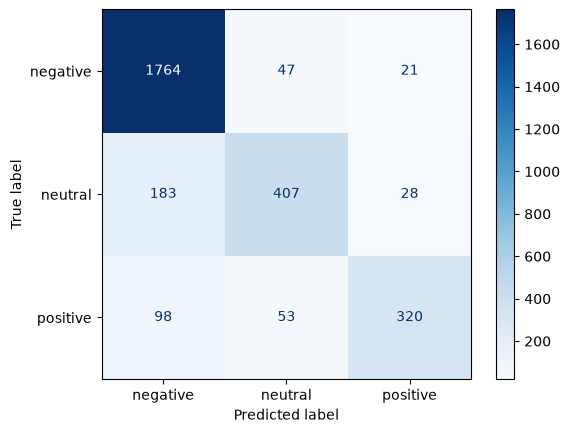

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

display(
    pd.DataFrame(
        cm,
        index=[f"Actual {label}" for label in labels],
        columns=[f"Predicted {label}" for label in labels]
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues", values_format="d")

plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Train an improved model
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

X_train_tfidf = vectorizer.transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

balanced_model.fit(X_train_tfidf, y_train)

# Evaluate the new model
balanced_predictions = balanced_model.predict(X_test_tfidf)

print(classification_report(y_test, balanced_predictions))

              precision    recall  f1-score   support

    negative       0.89      0.80      0.85      1832
     neutral       0.56      0.71      0.62       618
    positive       0.69      0.72      0.70       471

    accuracy                           0.77      2921
   macro avg       0.71      0.74      0.72      2921
weighted avg       0.79      0.77      0.78      2921



In [46]:
test_tweets = [
    "The flight was terrible and very disappointing.",
    "The flight was okay, nothing special.",
    "The flight was excellent and amazing!"
]


test_features = vectorizer.transform(test_tweets)
predictions = model.predict(test_features)

for tweet, sentiment in zip(test_tweets, predictions):
    print("Tweet:", tweet)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

NameError: name 'vectorizer' is not defined

In [47]:
import os

print("Current folder:", os.getcwd())
print("Models folder exists:", os.path.exists("../models"))
print("Files in models folder:")

if os.path.exists("../models"):
    print(os.listdir("../models"))

Current folder: e:\Brandpulse_AI\notebook
Models folder exists: True
Files in models folder:
['logistic_regression.pkl', 'tfidf_vectorizer.pkl']


In [48]:
import joblib


model = joblib.load("../models/logistic_regression.pkl")
vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")


tweet = ["I love this product, it is amazing!"]

#  Convert text into TF-IDF features
tweet_tfidf = vectorizer.transform(tweet)

# Predict sentiment
prediction = model.predict(tweet_tfidf)

print("Test tweet:", tweet[0])
print("Predicted sentiment:", prediction[0])

Test tweet: I love this product, it is amazing!
Predicted sentiment: positive


In [49]:
%pip install streamlit

   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   -----------------

In [50]:
import pandas as pd

print(df.columns)

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone', 'clean_text'],
      dtype='str')


In [51]:
print(df["sentiment"].value_counts())

KeyError: 'sentiment'

In [52]:
print(df.columns.tolist())

['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone', 'clean_text']


In [53]:
print(df["label"].value_counts())

KeyError: 'label'

In [54]:
print(df.columns.tolist())

['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone', 'clean_text']


In [55]:
print(df["airline_sentiment"].value_counts())

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


In [56]:
print(
    df.loc[
        df["airline_sentiment"] == "neutral",
        ["text", "airline_sentiment"]
    ].head(10)
)

                                                 text airline_sentiment
0                 @VirginAmerica What @dhepburn said.           neutral
2   @VirginAmerica I didn't today... Must mean I n...           neutral
7   @VirginAmerica Really missed a prime opportuni...           neutral
10  @VirginAmerica did you know that suicide is th...           neutral
23  @VirginAmerica will you be making BOS&gt;LAS n...           neutral
27  @VirginAmerica do you miss me? Don't worry we'...           neutral
29  @VirginAmerica LAX to EWR - Middle seat on a r...           neutral
31  @VirginAmerica Are the hours of operation for ...           neutral
35  Nice RT @VirginAmerica: Vibe with the moodligh...           neutral
38  @VirginAmerica when can I book my flight to Ha...           neutral


In [57]:
print("Model classes:", model.classes_)

Model classes: ['negative' 'neutral' 'positive']


In [58]:
test_tweets = [
    "The product was delivered today.",
    "The airline provided excellent service!",
    "The flight was terrible and delayed.",
    "My flight is scheduled for 5 PM.",
    "The airline has three types of tickets."
]

for tweet in test_tweets:
    features = vectorizer.transform([tweet])
    prediction = model.predict(features)[0]
    print(f"Tweet: {tweet}")
    print(f"Prediction: {prediction}")
    print("-" * 40)

Tweet: The product was delivered today.
Prediction: positive
----------------------------------------
Tweet: The airline provided excellent service!
Prediction: positive
----------------------------------------
Tweet: The flight was terrible and delayed.
Prediction: negative
----------------------------------------
Tweet: My flight is scheduled for 5 PM.
Prediction: negative
----------------------------------------
Tweet: The airline has three types of tickets.
Prediction: negative
----------------------------------------


In [59]:
# dataset actual neutral tweet here
neutral_tweets = df.loc[
    df["airline_sentiment"] == "neutral",
    "clean_text"
].dropna().head(10)

# checking model prediction 
for tweet in neutral_tweets:
    features = vectorizer.transform([tweet])
    prediction = model.predict(features)[0]

    print("Tweet:", tweet)
    print("Actual: neutral")
    print("Predicted:", prediction)
    print("-" * 50)

Tweet: What said.
Actual: neutral
Predicted: negative
--------------------------------------------------
Tweet: I didn't today... Must mean I need to take another trip!
Actual: neutral
Predicted: neutral
--------------------------------------------------
Tweet: Really missed a prime opportunity for Men Without Hats parody, there.
Actual: neutral
Predicted: negative
--------------------------------------------------
Tweet: did you know that suicide is the second leading cause of death among teens 10-24
Actual: neutral
Predicted: neutral
--------------------------------------------------
Tweet: will you be making BOS>LAS non stop permanently anytime soon?
Actual: neutral
Predicted: neutral
--------------------------------------------------
Tweet: do you miss me? Don't worry we'll be together very soon.
Actual: neutral
Predicted: negative
--------------------------------------------------
Tweet: LAX to EWR - Middle seat on a red eye. Such a noob maneuver. #sendambien #andchexmix
Actual: n

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Test dataset prediction
y_pred = model.predict(X_test)

# we check here every sentiment ki performance
print(classification_report(
    y_test,
    y_pred,
    target_names=model.classes_
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

              precision    recall  f1-score   support

    negative       0.83      0.93      0.88      1889
     neutral       0.66      0.52      0.58       580
    positive       0.81      0.61      0.70       459

    accuracy                           0.80      2928
   macro avg       0.77      0.69      0.72      2928
weighted avg       0.79      0.80      0.79      2928

Confusion Matrix:
[[1762   95   32]
 [ 248  300   32]
 [ 121   57  281]]


In [61]:
from collections import Counter

print("Training labels:", Counter(y_train))
print("Testing labels:", Counter(y_test))

Training labels: Counter({'negative': 7289, 'neutral': 2519, 'positive': 1904})
Testing labels: Counter({'negative': 1889, 'neutral': 580, 'positive': 459})


In [62]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Balanced model train
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

balanced_model.fit(X_train, y_train)

# Test data  predictions
balanced_pred = balanced_model.predict(X_test)


print(classification_report(y_test, balanced_pred))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    balanced_pred,
    labels=balanced_model.classes_
))

              precision    recall  f1-score   support

    negative       0.90      0.81      0.85      1889
     neutral       0.54      0.69      0.60       580
    positive       0.68      0.74      0.71       459

    accuracy                           0.77      2928
   macro avg       0.71      0.75      0.72      2928
weighted avg       0.80      0.77      0.78      2928

Confusion Matrix:
[[1528  274   87]
 [ 112  398   70]
 [  52   67  340]]


In [63]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(balanced_model, MODEL_DIR / "logistic_regression.pkl")
joblib.dump(vectorizer, MODEL_DIR / "tfidf_vectorizer.pkl")

print("Balanced model and vectorizer saved successfully!")

Balanced model and vectorizer saved successfully!


In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

for c in [0.1, 0.5, 1, 2, 5, 10]:
    test_model = LogisticRegression(
        C=c,
        max_iter=1000,
        random_state=42
    )

    test_model.fit(X_train, y_train)
    predictions = test_model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")

    print(
        f"C={c:<4} | "
        f"Accuracy={accuracy:.3f} | "
        f"Macro F1={macro_f1:.3f}"
    )

C=0.1  | Accuracy=0.736 | Macro F1=0.561
C=0.5  | Accuracy=0.795 | Macro F1=0.706
C=1    | Accuracy=0.800 | Macro F1=0.719
C=2    | Accuracy=0.802 | Macro F1=0.728
C=5    | Accuracy=0.799 | Macro F1=0.726
C=10   | Accuracy=0.788 | Macro F1=0.716


In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

tuned_model = LogisticRegression(
    C=2,
    max_iter=1000,
    random_state=42
)

tuned_model.fit(X_train, y_train)

tuned_pred = tuned_model.predict(X_test)

print(classification_report(y_test, tuned_pred))

              precision    recall  f1-score   support

    negative       0.84      0.92      0.88      1889
     neutral       0.64      0.54      0.59       580
    positive       0.81      0.64      0.72       459

    accuracy                           0.80      2928
   macro avg       0.76      0.70      0.73      2928
weighted avg       0.80      0.80      0.80      2928

